# 05. クラウド構成図とソフトウェアフロー図

<p><a href="https://colab.research.google.com/github/yuichi110/drawlib/blob/main/docs/jupyter/ja/05_architecture_and_flows.ipynb" target="_blank" rel="noopener noreferrer"></a></p>

`drawlib.diagrams` は 6 種類の専門ダイアグラム（`ArchitectureDiagram`、`FlowDiagram`、`SequenceDiagram`、`StateDiagram`、`ClassDiagram`、`ErDiagram`）を提供します。

<p align="center">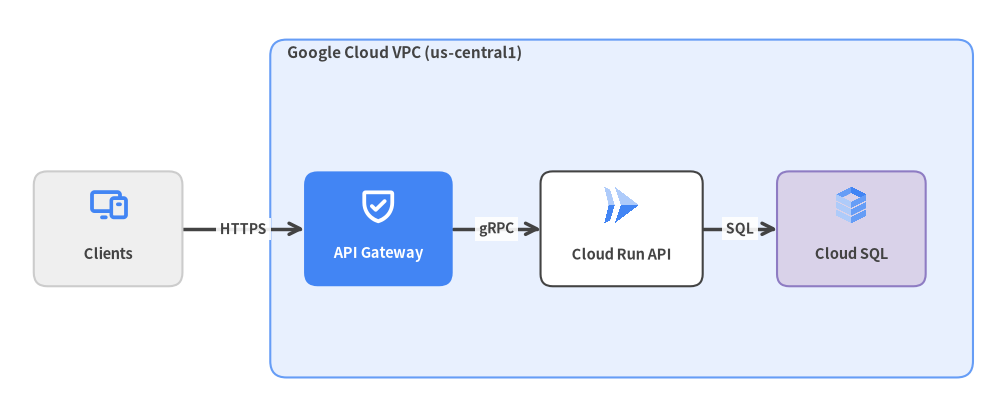</p>

<p align="center"><em>ArchitectureDiagram で構築したクラウド VPC トポロジ</em></p>

In [ ]:
!pip install -q drawlib

---

## 1. Python セルでフローステップを確認する

まず Python セルで認証フローの各ステップを確認します。

In [ ]:
flow_steps = [
    ("req", "Incoming Request"),
    ("auth", "Token Valid?"),
    ("allow", "Route to Worker"),
    ("deny", "Return 401"),
]
print("Flow steps:", [step[0] for step in flow_steps])

---

## 2. `FlowDiagram` による条件分岐フローの描画

`FlowDiagram` を使って JWT トークン検証の条件分岐フローをインライン描画します。

In [ ]:
from drawlib.canvas import show, setup
from drawlib.diagrams.flow import Decision, End, FlowDiagram, Process, Start
from drawlib.styles import Styles

setup(width=128, height=48, cwd=True)

flow = FlowDiagram(
    node_style=Styles.Neutral.patch(shape_r=1.8),
    edge_style=Styles.DarkBold,
    edge_text_style=Styles.DarkBold.patch(text_size=10.0),
)

n_start = flow.add(
    Start("Incoming Request", width=26.0, height=11.0, text_style=Styles.DarkBold.patch(text_size=10.2)),
    xy=(18.0, 26.0),
)
n_check = flow.add(
    Decision(
        "JWT Valid?",
        width=26.0,
        height=15.0,
        style=Styles.PrimaryFlat,
        text_style=Styles.WhiteBold.patch(text_size=10.5),
    ),
    xy=(58.0, 26.0),
)
n_allow = flow.add(
    Process(
        "Forward to Service",
        width=28.0,
        height=11.0,
        style=Styles.PrimaryNeutral,
        text_style=Styles.DarkBold.patch(text_size=10.2),
    ),
    xy=(104.0, 26.0),
)
n_deny = flow.add(
    End(
        "Reject (401)",
        width=28.0,
        height=11.0,
        style=Styles.SecondaryNeutral,
        text_style=Styles.DarkBold.patch(text_size=10.2),
    ),
    xy=(104.0, 10.0),
)

flow.connect(n_start, n_check)
flow.connect(n_check, n_allow, label="Yes", start_side="right", end_side="left")
flow.connect(n_check, n_deny, label="No", start_side="bottom", end_side="left", routing="orthogonal")
flow.draw(xy=(2.0, 2.0))

show()